# Tareas pendientes por día por área — API LISA (SGA)

Complemento de `piezas_por_dia.ipynb`: en lugar del volumen movido, aquí se reconstruye el
**backlog — cuántas tareas estaban pendientes al cierre de cada día** en cada área del almacén.

| Endpoint | Área | Campo de estatus | Notas |
|---|---|---|---|
| `SGAENTRADAS` | RECIBO | `status_tarea` | |
| `SGACOLOCACION2` | UBICACIONES | `status` | |
| `SGAPREPARACION` (v1) | SURTIDO | — *no trae estatus* | detalle por línea → se deduplica por tarea |
| `SGAEMBALAJE` | VERIFICACIÓN | `estatus_tarea` | |

> **Por qué `SGAPREPARACION` (v1) y no `SGAPREPARACION2`:** el `_2` es un resumen agregado por
> usuario/día **sin estatus ni fechas por tarea**, así que no permite calcular pendientes. La v1 sí
> trae `fecha_gen` / `fecha_inicio` / `fecha_fin` por tarea (en su detalle de líneas). Ojo: todas sus
> líneas tienen `fecha_inicio`, es decir sólo expone tareas que llegaron a iniciarse — su backlog
> refleja el arrastre entre días, no tareas nunca atendidas.

**Definición — pendiente al cierre del día `D`:** tarea con `fecha_gen ≤ D` que aún no salía de
pendiente en `D`. La *salida de pendiente* es `fecha_inicio` (inicio de la tarea en el handheld),
con fallback a `fecha_fin` para tareas cerradas sin inicio registrado; las tareas sin ninguna de las
dos siguen pendientes hasta el final de la serie. Las **anuladas se excluyen**. La serie es el
acumulado diario de altas (generación) menos bajas (inicio).

Códigos de estatus observados: `C` Cerrado · `P` Pendiente · `A` Anulado · `E` En Espera ·
`B` Bloqueado · `R` Realizándose.

Notas de importación:

- Los filtros de fecha son **cota inferior**: una fecha temprana trae toda la historia en una llamada.
- `sga_preparacion` no acepta `p_almacen` (contrato `edisa.json`), se filtra en pandas; son ~65 mil
  líneas y la llamada tarda ~1 minuto, por eso el cliente se instancia con `timeout=240`.
- La serie de RECIBO termina antes que las demás (el endpoint deja de reportar el 26-jun-2026).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter

from lisa_client import LisaClient

ALMACEN = "5460D"
FECHA_DESDE = "01/01/2025"  # cota inferior: trae toda la historia disponible

client = LisaClient(timeout=240)  # sga_preparacion (detalle por línea) tarda ~1 min

## 1. Importación desde el API

Los registros vienen en `registros.reg` (un `dict` cuando hay un solo registro, una lista en otro caso).

In [2]:
def a_dataframe(respuesta: dict) -> pd.DataFrame:
    """Convierte la respuesta del API (registros.reg) en un DataFrame."""
    registros = (respuesta.get("registros") or {}).get("reg") or []
    if isinstance(registros, dict):  # un solo registro llega como dict
        registros = [registros]
    return pd.DataFrame(registros)


df_entradas = a_dataframe(client.entradas_almacen(fecha_gen=FECHA_DESDE, almacen=ALMACEN))
df_colocacion = a_dataframe(client.colocacion_2(fecha_gen=FECHA_DESDE, almacen=ALMACEN))
df_preparacion = a_dataframe(client.preparacion(fecha_gen=FECHA_DESDE))  # v1: sin p_almacen
df_preparacion = df_preparacion[df_preparacion["almacen"] == ALMACEN]
df_embalaje = a_dataframe(client.embalaje(fecha_gen=FECHA_DESDE, almacen=ALMACEN))

for nombre, df in [
    ("SGAENTRADAS", df_entradas),
    ("SGACOLOCACION2", df_colocacion),
    ("SGAPREPARACION", df_preparacion),
    ("SGAEMBALAJE", df_embalaje),
]:
    print(f"{nombre:16s} {len(df):>7,} registros · {df.shape[1]} columnas")

20:13:30 [INFO] POST /galileo/lisa/geninf/isp/sga_entradas | body: {'p_fecha_gen': '01/01/2025', 'p_almacen': '5460D'}


20:13:34 [INFO] POST /galileo/lisa/geninf/isp/sga_colocacion_2 | body: {'p_fecha_gen': '01/01/2025', 'p_almacen': '5460D'}


20:13:44 [INFO] POST /galileo/lisa/geninf/isp/sga_preparacion | body: {'p_fecha_gen': '01/01/2025'}


20:14:46 [INFO] POST /galileo/lisa/geninf/isp/sga_embalaje | body: {'p_fecha_gen': '01/01/2025', 'p_almacen': '5460D'}


SGAENTRADAS        3,405 registros · 34 columnas
SGACOLOCACION2     7,365 registros · 54 columnas
SGAPREPARACION    65,597 registros · 37 columnas
SGAEMBALAJE       15,593 registros · 33 columnas


## 2. Backlog diario por área

Cada tarea aporta un **alta** el día de `fecha_gen` y una **baja** el día en que deja de estar
pendiente (`fecha_inicio`, con fallback a `fecha_fin`); el backlog al cierre de cada día es el
acumulado de altas menos bajas. Una tarea generada e iniciada el mismo día no aparece en el
backlog de cierre. `SGAPREPARACION` se deduplica de líneas a tareas antes del cálculo.

In [3]:
ESTATUS_ANULADA = "A"


def fechas_de(s: pd.Series) -> pd.Series:
    return pd.to_datetime(s, format="mixed", dayfirst=True, errors="coerce").dt.normalize()


def tareas_normalizadas(df: pd.DataFrame, col_status: str | None = None):
    """Por tarea: día de generación (`gen`) y día en que dejó de estar pendiente (`salida`).

    `salida` = fecha_inicio con fallback a fecha_fin; NaT = sigue pendiente.
    Excluye anuladas. Devuelve (tareas, n_anuladas).
    """
    n_anuladas = 0
    if col_status is not None:
        anuladas = df[col_status].eq(ESTATUS_ANULADA)
        n_anuladas = int(anuladas.sum())
        df = df[~anuladas]
    tareas = pd.DataFrame(
        {
            "gen": fechas_de(df["fecha_gen"]),
            "salida": fechas_de(df["fecha_inicio"]).fillna(fechas_de(df["fecha_fin"])),
        }
    ).dropna(subset=["gen"])
    return tareas, n_anuladas


def backlog_diario(tareas: pd.DataFrame) -> pd.Series:
    """Tareas pendientes al cierre de cada día: acumulado de altas (gen) menos bajas (salida)."""
    fin = pd.Series([tareas["gen"].max(), tareas["salida"].max()]).max()
    dias = pd.date_range(tareas["gen"].min(), fin, freq="D")
    altas = tareas["gen"].value_counts().reindex(dias, fill_value=0)
    bajas = tareas["salida"].dropna().value_counts().reindex(dias, fill_value=0)
    return (altas - bajas).cumsum()


# SURTIDO: sga_preparacion es detalle por línea → se deduplica a nivel tarea
prep = df_preparacion.copy()
for c in ("fecha_gen", "fecha_inicio", "fecha_fin"):
    prep[c] = pd.to_datetime(prep[c], format="mixed", dayfirst=True, errors="coerce")
prep_tareas = prep.groupby(["empresa", "tarea"], as_index=False).agg(
    fecha_gen=("fecha_gen", "min"),
    fecha_inicio=("fecha_inicio", "min"),
    fecha_fin=("fecha_fin", "max"),
)
print(f"SGAPREPARACION: {len(df_preparacion):,} líneas → {len(prep_tareas):,} tareas")

# Paleta categórica en orden fijo (validada para visión de color y contraste)
AREAS = {}
for nombre, df, col_status, color, nota in [
    ("RECIBO (SGAENTRADAS)", df_entradas, "status_tarea", "#2a78d6", ""),
    ("UBICACIONES (SGACOLOCACION2)", df_colocacion, "status", "#1baf7a", ""),
    ("SURTIDO (SGAPREPARACION)", prep_tareas, None, "#eda100",
     "sólo tareas que llegaron a iniciarse"),
    ("VERIFICACIÓN (SGAEMBALAJE)", df_embalaje, "estatus_tarea", "#008300", ""),
]:
    tareas, n_anuladas = tareas_normalizadas(df, col_status)
    AREAS[nombre] = {
        "serie": backlog_diario(tareas),
        "tareas": tareas,
        "anuladas": n_anuladas,
        "color": color,
        "nota": nota,
    }

SGAPREPARACION: 65,597 líneas → 9,731 tareas


## 3. Resumen por área (vista de tabla)

`pendientes al cierre de la serie` es el backlog vigente al último día con datos del endpoint;
`sin iniciar` son las tareas que a esa fecha no registran ni inicio ni fin. `mínimo` no puede ser
negativo (eso señalaría inconsistencias de fechas en el API); un mínimo mayor que cero — como en
VERIFICACIÓN — es arrastre permanente: el área nunca amanece sin trabajo pendiente.

In [4]:
resumen = pd.DataFrame(
    [
        {
            "área": nombre,
            "desde": a["serie"].index.min().date(),
            "hasta": a["serie"].index.max().date(),
            "máximo": int(a["serie"].max()),
            "día del máximo": a["serie"].idxmax().date(),
            "pendientes al cierre de la serie": int(a["serie"].iloc[-1]),
            "sin iniciar": int(a["tareas"]["salida"].isna().sum()),
            "anuladas excluidas": a["anuladas"],
            "días en cero": f"{(a['serie'] == 0).mean():.0%}",
            "mínimo": int(a["serie"].min()),
        }
        for nombre, a in AREAS.items()
    ]
).set_index("área")
resumen

,desde,hasta,máximo,día del máximo,pendientes al cierre de la serie,sin iniciar,anuladas excluidas,días en cero,mínimo
área,,,,,,,,,
RECIBO (SGAENTRADAS),2026-01-02,2026-06-26,0,2026-01-02,0,0,434,100%,0
UBICACIONES (SGACOLOCACION2),2026-01-06,2026-07-06,172,2026-06-18,10,10,79,17%,0
SURTIDO (SGAPREPARACION),2026-02-09,2026-07-07,291,2026-03-17,0,0,0,16%,0
VERIFICACIÓN (SGAEMBALAJE),2026-02-09,2026-07-07,310,2026-05-04,143,143,20,0%,26


In [5]:
# Tabla diaria completa (una columna por área) — últimos 10 días
tabla_diaria = pd.DataFrame(
    {f"{nombre} [pendientes]": a["serie"] for nombre, a in AREAS.items()}
)
tabla_diaria.index.name = "fecha"
tabla_diaria.tail(10)

,RECIBO (SGAENTRADAS) [pendientes],UBICACIONES (SGACOLOCACION2) [pendientes],SURTIDO (SGAPREPARACION) [pendientes],VERIFICACIÓN (SGAEMBALAJE) [pendientes]
fecha,,,,
2026-06-28,NaN,14.0,6.0,148.0
2026-06-29,NaN,12.0,0.0,128.0
2026-06-30,NaN,12.0,1.0,215.0
2026-07-01,NaN,10.0,1.0,225.0
2026-07-02,NaN,10.0,0.0,218.0
2026-07-03,NaN,22.0,1.0,198.0
2026-07-04,NaN,22.0,1.0,198.0
2026-07-05,NaN,22.0,1.0,198.0
2026-07-06,NaN,10.0,0.0,76.0


## 4. Tareas pendientes al cierre del día por área

Un subplot por área con el eje de fechas compartido; las escalas verticales son independientes.
El backlog es un *stock* (no un flujo): sube cuando se genera más de lo que se inicia y baja al
revés. Una meseta sostenida arriba de cero es trabajo arrastrado, y las tareas que nunca se
inician sostienen el piso de la curva hasta el final de la serie (es el caso de VERIFICACIÓN,
que cierra con todas sus tareas sin iniciar acumuladas). RECIBO plano en cero significa que las
recepciones se inician el mismo día en que se generan.

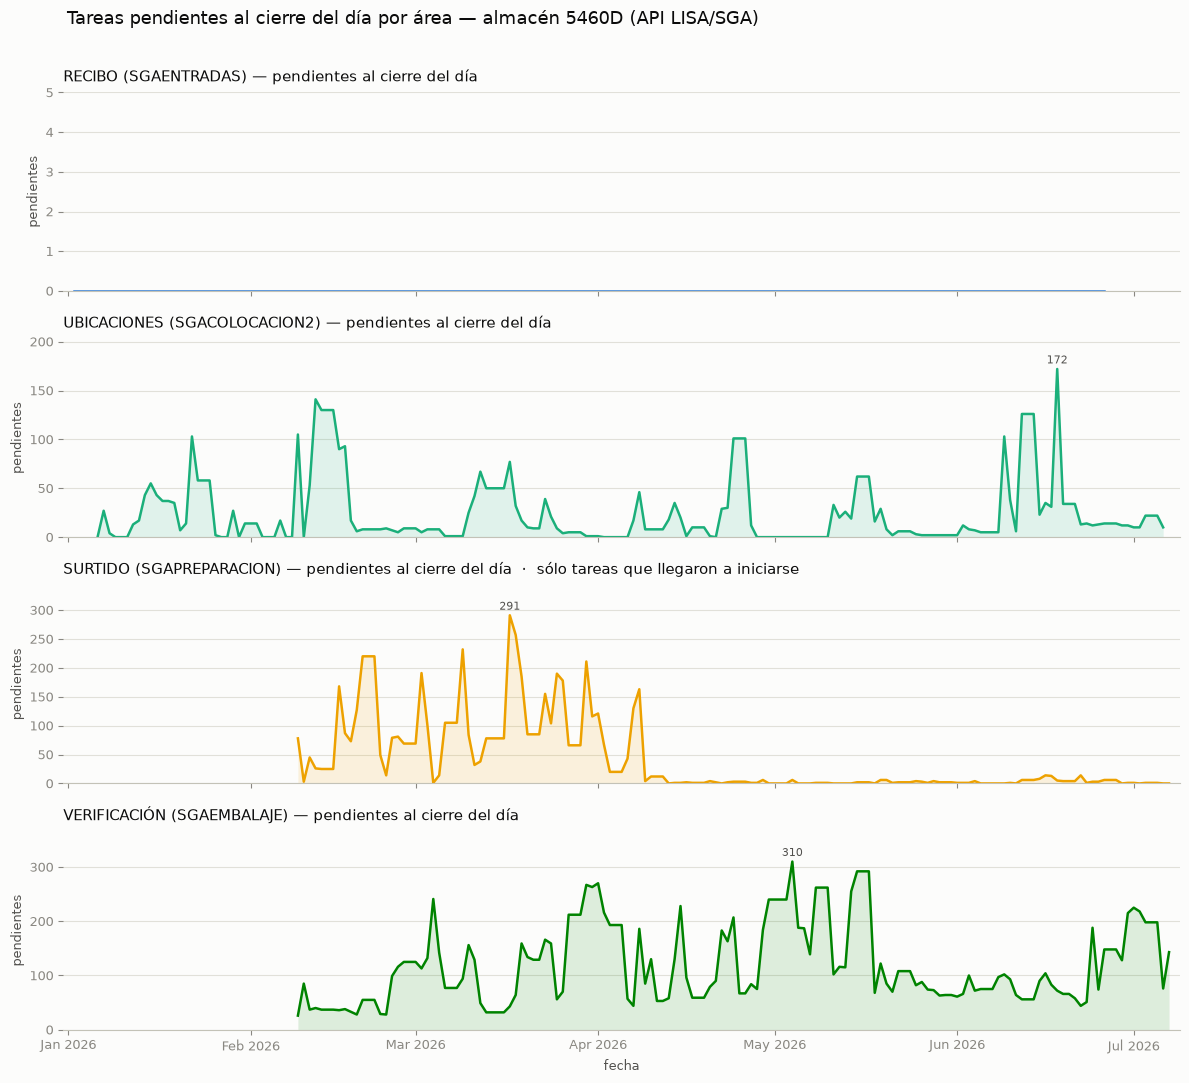

In [6]:
INK = "#0b0b0b"
INK_2 = "#52514e"
MUTED = "#898781"
GRID = "#e1e0d9"
BASELINE = "#c3c2b7"
SURFACE = "#fcfcfb"

fmt_miles = FuncFormatter(lambda v, _: f"{v:,.0f}")

fig, axes = plt.subplots(len(AREAS), 1, figsize=(12, 11), sharex=True)
fig.patch.set_facecolor(SURFACE)

for ax, (nombre, a) in zip(axes, AREAS.items()):
    s = a["serie"]
    ax.fill_between(s.index, s.values, color=a["color"], alpha=0.12, linewidth=0)
    ax.plot(s.index, s.values, color=a["color"], linewidth=1.8)

    titulo = f"{nombre} — pendientes al cierre del día"
    if a["nota"]:
        titulo += f"  ·  {a['nota']}"
    ax.set_title(titulo, loc="left", fontsize=11, color=INK, pad=8)

    ax.set_facecolor(SURFACE)
    ax.set_ylabel("pendientes", fontsize=9, color=INK_2)
    ax.set_ylim(0, max(s.max() * 1.18, 5))
    ax.margins(x=0.01)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    for lado in ("top", "right", "left"):
        ax.spines[lado].set_visible(False)
    ax.spines["bottom"].set_color(BASELINE)
    ax.tick_params(colors=MUTED, labelsize=9)
    ax.yaxis.set_major_formatter(fmt_miles)

    # etiqueta directa del pico
    if s.max() > 0:
        dia_max = s.idxmax()
        ax.annotate(
            f"{int(s.max()):,}",
            xy=(dia_max, s.max()),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            fontsize=8,
            color=INK_2,
        )

axes[-1].xaxis.set_major_locator(mdates.MonthLocator())
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
axes[-1].set_xlabel("fecha", fontsize=9, color=INK_2)

fig.suptitle(
    f"Tareas pendientes al cierre del día por área — almacén {ALMACEN} (API LISA/SGA)",
    fontsize=13,
    color=INK,
    x=0.06,
    ha="left",
)
fig.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()